# Notebook 1 of 2 — Adaptive Gaussian COST sampling with Julia AC-OPF

Based on the uploaded **`sampling_data_cost(3).ipynb`** and the existing LOAD / VOLTAGE / DERATE / KILLGEN notebooks. **This is cost-only perturbation**: choose approximately 10% of eligible polynomial-quadratic generators (3 coefficients) and approximately 10% of polynomial-linear generators (2 coefficients), sample their new cost coefficients, clip negatives to zero, and keep originally constant coefficients fixed. The two cost families have **separate Gaussian mean and covariance**.

Julia's `verify_scenario_json()` is used **only to guide accepted-only Gaussian updates**; it does not produce GridSFM's predicted-feasibility labels. No early stopping. A **single randomized initial scale** is applied to the empirical covariance of each cost family.

The original reference defaults to 100 iterations × 200 scenarios, but the inexpensive smoke-test defaults here follow the other notebooks (10 × 2). Increase these values when ready for actual experiments. Notebook 2 consumes the scenario archive generated here.


## 1. Imports, paths, and grid dataset


In [1]:
import csv
import hashlib
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from juliacall import Main as jl

DATASET_NAME = "alabama"       # Match Notebook 2; use "texas" for Texas
TIME_SLICE = "16h"
DATASET_LABEL = DATASET_NAME.replace("_", " ").title()

def find_project_root():
    cwd = Path.cwd().resolve()
    for parent in (cwd, *cwd.parents):
        for candidate in (parent, parent / "GridSFM"):
            if (candidate / "model").is_dir() and (candidate / "verifier").is_dir():
                return candidate.resolve()
    raise FileNotFoundError("Open Jupyter from the GridSFM project or its notebook/ folder")

PROJECT_ROOT = find_project_root()
GRID_ROOT = next((p for p in (PROJECT_ROOT / "power_grid", PROJECT_ROOT.parent / "power_grid")
                  if (p / "US" / "gridsfm_data").is_dir()), None)
if GRID_ROOT is None:
    raise FileNotFoundError("Cannot locate power_grid/US/gridsfm_data")
DATA_PATH = GRID_ROOT / "US" / "gridsfm_data" / TIME_SLICE / f"{DATASET_NAME}_model.json"
JULIA_SCRIPT = PROJECT_ROOT / "verifier" / "acopf_verifier.jl"
OUTPUT_DIR = PROJECT_ROOT / "results" / "gaussian_cost" / DATASET_NAME
SCENARIO_PATH = OUTPUT_DIR / "acopf_labeled_scenarios.npz"
assert DATA_PATH.is_file(), DATA_PATH
assert JULIA_SCRIPT.is_file(), JULIA_SCRIPT
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
with DATA_PATH.open("r", encoding="utf-8") as f:
    data = json.load(f)
CASE_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert isinstance(data.get("gen"), dict) and isinstance(data.get("bus"), dict)
print("Dataset:", DATASET_LABEL, "| file:", DATA_PATH)
print("Julia:", JULIA_SCRIPT, "| output:", OUTPUT_DIR)


Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython
Dataset: Alabama | file: /Users/punrong_rany/Desktop/Projects/GridSFM/power_grid/US/gridsfm_data/16h/alabama_model.json
Julia: /Users/punrong_rany/Desktop/Projects/GridSFM/verifier/acopf_verifier.jl | output: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_cost/alabama


## 2. Identify quadratic and linear polynomial cost pools


In [2]:
# Original source: model==2, ncost==3 => [c2,c1,c0]; ncost==2 => [c1,c0].
quadratic_ids, linear_ids = [], []
for raw_id, g in data["gen"].items():
    gid = str(raw_id)
    if int(g.get("gen_status", 0)) != 1 or int(g.get("model", -1)) != 2:
        continue
    coeff = g.get("cost", [])
    if not isinstance(coeff, (list, tuple)):
        continue
    ncost = int(g.get("ncost", -1))
    if len(coeff) != ncost or not np.isfinite(np.asarray(coeff, dtype=float)).all():
        continue
    if ncost == 3:
        quadratic_ids.append(gid)
    elif ncost == 2:
        linear_ids.append(gid)

if not quadratic_ids and not linear_ids:
    raise ValueError("No active polynomial generators with ncost=2 or 3; cannot run COST mode")
quadratic_costs = (np.asarray([data["gen"][gid]["cost"] for gid in quadratic_ids], dtype=float)
                   if quadratic_ids else np.empty((0,3),dtype=float))
linear_costs = (np.asarray([data["gen"][gid]["cost"] for gid in linear_ids], dtype=float)
                if linear_ids else np.empty((0,2),dtype=float))
quad_n = len(quadratic_ids)
linear_n = len(linear_ids)
FRACTION_COST_PERTURBED = 0.10  # Proportion sampled from EACH available cost family
quad_selected_n = max(1, round(FRACTION_COST_PERTURBED * quad_n)) if quad_n else 0
linear_selected_n = max(1, round(FRACTION_COST_PERTURBED * linear_n)) if linear_n else 0

# Canonical GridSFM representation: [cp2,cp1,cp0]. Linear cost is [0,c1,c0].
gen_ids = quadratic_ids + linear_ids
family = np.asarray(["quadratic"] * quad_n + ["linear"] * linear_n, dtype=str)
original_cp = np.zeros((len(gen_ids), 3), dtype=np.float64)
if quad_n: original_cp[:quad_n] = quadratic_costs
if linear_n: original_cp[quad_n:, 1:] = linear_costs
gen_index = {gid:i for i,gid in enumerate(gen_ids)}
assert len(set(gen_ids)) == len(gen_ids)
print(f"Quadratic: {quad_n} eligible, {quad_selected_n} selected per scenario; shape {quadratic_costs.shape}")
print(f"Linear: {linear_n} eligible, {linear_selected_n} selected per scenario; shape {linear_costs.shape}")
print("Total cost-bearing generators:", len(gen_ids))


Quadratic: 49 eligible, 5 selected per scenario; shape (49, 3)
Linear: 3 eligible, 1 selected per scenario; shape (3, 2)
Total cost-bearing generators: 52


## 3. Initialize the standardized Julia AC-OPF verifier


In [3]:
jl.include(str(JULIA_SCRIPT.resolve()))
# Module name is GridSFMLoadVerifier in the earlier refactor and ACOPFVerifier
# in some notebook versions. Both expose the same general-purpose API.
if hasattr(jl, "ACOPFVerifier"):
    VERIFIER = jl.ACOPFVerifier
elif hasattr(jl, "GridSFMLoadVerifier"):
    VERIFIER = jl.GridSFMLoadVerifier
else:
    raise RuntimeError("Julia verifier module not found after include()")
summary = json.loads(str(VERIFIER.initialize_case(str(DATA_PATH.resolve()))))
print("Verifier initialized:", summary)
assert "gen" in summary.get("supported_modes", []), "This verifier does not support gen cost patches"


Verifier initialized: {'n_buses': 494, 'baseMVA': 100.0, 'supported_modes': ['branch', 'bus', 'gen', 'load'], 'initialized': True, 'n_loads': 494, 'n_generators': 55, 'n_branches': 864, 'per_unit': True}


## 4. Shared verifier wrapper, COST patch, and baseline test


In [4]:
def verify_scenario(patch):
    start = time.perf_counter()
    try:
        if not isinstance(patch, dict) or not patch:
            raise ValueError("patch must be a nonempty dictionary")
        raw = VERIFIER.verify_scenario_json(json.dumps(patch, allow_nan=False))
        result = json.loads(str(raw))
        result["elapsed_s"] = time.perf_counter() - start
        return result
    except Exception as exc:
        return {
            "accepted": False, "status": "CALL_ERROR", "objective": None,
            "solve_time": None, "reason": str(exc)[:1000],
            "termination_status": "ERROR", "primal_status": "UNKNOWN",
            "elapsed_s": time.perf_counter() - start,
        }


def build_cost_patch(candidate_cp, selected_ids):
    values = np.asarray(candidate_cp, dtype=np.float64)
    if values.shape != original_cp.shape or not np.isfinite(values).all():
        raise ValueError(f"Expected finite canonical cost matrix {original_cp.shape}, got {values.shape}")
    selected_ids = [str(gid) for gid in selected_ids]
    if not selected_ids or len(selected_ids) != len(set(selected_ids)):
        raise ValueError("selected_ids must be nonempty and unique")
    if any(gid not in gen_index for gid in selected_ids):
        raise ValueError("Patch references unknown/ineligible generator ID")
    patch = {}
    for gid in selected_ids:
        i = gen_index[gid]
        if family[i] == "quadratic":
            cost = values[i].tolist()                    # [c2,c1,c0]
        else:
            if not np.isclose(values[i,0], 0.0, atol=1e-12):
                raise ValueError(f"Linear generator {gid} must have cp2=0")
            cost = values[i,1:].tolist()                  # [c1,c0]
        if not np.isfinite(cost).all():
            raise ValueError(f"Invalid non-finite cost for generator {gid}")
        patch[gid] = {"cost": [float(x) for x in cost]}
    # Julia infers model/ncost from each unchanged generator's cost model.
    return {"gen": patch}


def verify_acopf(candidate_cp, selected_ids):
    return verify_scenario(build_cost_patch(candidate_cp, selected_ids))

print(f"Verifying original {DATASET_LABEL} case")
baseline_gen_id = gen_ids[0]
baseline_result = verify_acopf(original_cp, [baseline_gen_id])
print("Baseline:\n", baseline_result)
if not baseline_result.get("accepted", False):
    raise RuntimeError("Original case not confirmed by Julia AC-OPF: " + str(baseline_result))


Verifying original Alabama case
Baseline:
 {'stage': 'opf', 'modes': ['gen'], 'termination_status': 'LOCALLY_SOLVED', 'objective': 198538.08988997107, 'primal_status': 'FEASIBLE_POINT', 'reason': '', 'warnings': [], 'applied_components': {'gen': 1}, 'solve_time': 2.7179548740386963, 'accepted': True, 'status': 'OPF_SOLVED', 'elapsed_s': 9.072332083975198}


## 5. Initialize two Gaussian distributions (with random initial scale)


In [5]:
SEED = 42
iterations = 10
samples_per_iteration = 2
alpha = 0.30
INITIAL_SCALE_MIN, INITIAL_SCALE_MAX = 1.0, 1.8
COV_REG = 1e-8
assert iterations >= 1 and samples_per_iteration >= 1 and 0 < alpha <= 1
assert 0 < INITIAL_SCALE_MIN <= INITIAL_SCALE_MAX

rng = np.random.default_rng(SEED)
scale_rng = np.random.default_rng(SEED + 1)
INITIAL_SCALE = float(scale_rng.uniform(INITIAL_SCALE_MIN, INITIAL_SCALE_MAX))


def init_cost_gaussian(arr):
    n, dim = arr.shape
    if not n:
        return np.zeros(dim), np.zeros((dim,dim)), np.ones(dim,dtype=bool)
    mu = np.mean(arr,axis=0)
    base_cov = np.cov(arr,rowvar=False,bias=True) if n>=2 else np.zeros((dim,dim))
    cov = INITIAL_SCALE**2 * np.atleast_2d(base_cov)
    fixed = np.isclose(np.std(arr,axis=0),0.0,atol=1e-12)
    # Preserve dataset-constant coefficients exactly, including linear c0.
    cov[fixed,:] = 0.0
    cov[:,fixed] = 0.0
    cov[~fixed,~fixed] += COV_REG
    return mu.astype(float), cov, fixed

quad_mu,quad_cov,quad_fixed = init_cost_gaussian(quadratic_costs)
linear_mu,linear_cov,linear_fixed = init_cost_gaussian(linear_costs)
initial_quad_mu,initial_quad_cov = quad_mu.copy(),quad_cov.copy()
initial_linear_mu,initial_linear_cov = linear_mu.copy(),linear_cov.copy()

history, verification_log, candidates_log, selected_mask_log = [],[],[],[]
labels_log, iteration_log, scenario_log, status_log, termination_log, primal_log = [],[],[],[],[],[]
last_original_quad = last_proposed_quad = last_applied_quad = None
last_original_linear = last_proposed_linear = last_applied_linear = None
print("Initial scale:", INITIAL_SCALE)
print("Quadratic mean [c2,c1,c0]:",quad_mu,"std:",np.sqrt(np.diag(quad_cov)),"fixed:",quad_fixed)
print("Linear mean [c1,c0]:",linear_mu,"std:",np.sqrt(np.diag(linear_cov)),"fixed:",linear_fixed)


Initial scale: 1.5218394101607287
Quadratic mean [c2,c1,c0]: [ 351.04811601 1956.51020408   15.30612245] std: [ 997.57797606 1794.65928907   33.69465221] fixed: [False False False]
Linear mean [c1,c0]: [1000.    0.] std: [0. 0.] fixed: [ True  True]


## 6. Sample a COST scenario, independently choosing each cost family


In [6]:
def sample_family(rng, source, mean, cov, fixed_mask, n_selected, n_scenarios):
    n,dim = source.shape
    if n_selected == 0:
        empty=(n_scenarios,0,dim)
        return np.empty((n_scenarios,0),dtype=int),np.empty(empty),np.empty(empty),np.empty(empty),0.0
    indices = np.stack([rng.choice(n,size=n_selected,replace=False) for _ in range(n_scenarios)])
    raw = rng.multivariate_normal(mean,cov,size=(n_scenarios,n_selected),check_valid="raise")
    applied = np.maximum(raw,0.0) # original cost notebook rule
    if np.any(fixed_mask):
        applied[:,:,fixed_mask] = mean[fixed_mask]
    fraction_clipped=float(np.mean(raw<0.0))
    originals = source[indices]
    return indices,raw,applied,originals,fraction_clipped


def sample_cost_scenarios(rng,n_scenarios):
    qi,qr,qa,qo,qclip = sample_family(rng,quadratic_costs,quad_mu,quad_cov,quad_fixed,quad_selected_n,n_scenarios)
    li,lr,la,lo,lclip = sample_family(rng,linear_costs,linear_mu,linear_cov,linear_fixed,linear_selected_n,n_scenarios)
    full = np.broadcast_to(original_cp,(n_scenarios,*original_cp.shape)).copy()
    chosen = np.zeros((n_scenarios,len(gen_ids)),dtype=bool)
    for s in range(n_scenarios):
        if quad_selected_n:
            full[s,qi[s]] = qa[s]
            chosen[s,qi[s]] = True
        if linear_selected_n:
            full[s,quad_n+li[s],1:] = la[s]
            chosen[s,quad_n+li[s]] = True
    return full,chosen,(qi,qr,qa,qo,qclip),(li,lr,la,lo,lclip)


def update_distribution(mu,cov,fixed,accepted_arrays,dim):
    if not accepted_arrays:
        return mu,cov
    arr = np.concatenate(accepted_arrays,axis=0).reshape(-1,dim)
    empirical_mu = np.mean(arr,axis=0)
    empirical_cov = np.cov(arr,rowvar=False,bias=True) if len(arr)>=2 else cov.copy()
    new_mu = (1-alpha)*mu + alpha*empirical_mu
    new_cov = (1-alpha)*cov + alpha*empirical_cov
    new_cov = (new_cov+new_cov.T)/2
    new_mu[fixed] = mu[fixed]
    new_cov[fixed,:] = 0.0;new_cov[:,fixed] = 0.0
    new_cov[~fixed,~fixed] += COV_REG
    return new_mu,new_cov


## 7. Adaptive sampling with Julia, accepted-only updates, and checkpoints


In [7]:
for iteration in range(iterations):
    full, chosen, q, l = sample_cost_scenarios(rng,samples_per_iteration)
    qi,qr,qa,qo,qclip = q
    li,lr,la,lo,lclip = l
    accepted_q,accepted_l = [],[]
    accepted_count = 0
    for s in range(samples_per_iteration):
        ids = [gen_ids[i] for i in np.flatnonzero(chosen[s])]
        result = verify_acopf(full[s], ids)
        accepted = bool(result.get("accepted",False))
        accepted_count += int(accepted)
        verification_log.append({"iteration":iteration+1,"scenario":s+1,
            "n_quadratic_changed":int(quad_selected_n),"n_linear_changed":int(linear_selected_n),
            "selected_generator_ids":",".join(ids),**result})
        candidates_log.append(full[s].copy())
        selected_mask_log.append(chosen[s].copy())
        labels_log.append(int(accepted))
        iteration_log.append(iteration+1);scenario_log.append(s+1)
        status_log.append(str(result.get("status","UNKNOWN")))
        termination_log.append(str(result.get("termination_status","UNKNOWN")))
        primal_log.append(str(result.get("primal_status","UNKNOWN")))
        if accepted:
            if quad_selected_n: accepted_q.append(qa[s].copy())
            if linear_selected_n: accepted_l.append(la[s].copy())
        print(f"Iteration {iteration+1}/{iterations}, sample {s+1}/{samples_per_iteration}: "
              f"Julia={result.get('status')} ({result.get('termination_status')}) ",flush=True)
        if result.get("reason"):
            print("  Reason:",str(result["reason"])[:180],flush=True)

    quad_mu,quad_cov=update_distribution(quad_mu,quad_cov,quad_fixed,accepted_q,3)
    linear_mu,linear_cov=update_distribution(linear_mu,linear_cov,linear_fixed,accepted_l,2)
    history.append(dict(iteration=iteration+1,accepted_count=accepted_count,
        rejected_count=samples_per_iteration-accepted_count,
        acceptance_rate=accepted_count/samples_per_iteration,
        quad_mu=quad_mu.copy(),quad_std=np.sqrt(np.diag(quad_cov)),quad_cov=quad_cov.copy(),
        linear_mu=linear_mu.copy(),linear_std=np.sqrt(np.diag(linear_cov)),linear_cov=linear_cov.copy(),
        quad_clipped=qclip,linear_clipped=lclip,updated=bool(accepted_count)))
    last_original_quad,last_proposed_quad,last_applied_quad=qo,qr,qa
    last_original_linear,last_proposed_linear,last_applied_linear=lo,lr,la

    # Save every scenario after every iteration, not only the final accepted ones.
    np.savez_compressed(SCENARIO_PATH,
        candidates=np.stack(candidates_log).astype(np.float64),
        selected_mask=np.stack(selected_mask_log).astype(np.int8),
        original_costs=original_cp.astype(np.float64),
        gen_ids=np.asarray(gen_ids,dtype=str), cost_family=family,
        quadratic_ids=np.asarray(quadratic_ids,dtype=str),linear_ids=np.asarray(linear_ids,dtype=str),
        accepted=np.asarray(labels_log,dtype=np.int8),
        iteration=np.asarray(iteration_log,dtype=int),scenario=np.asarray(scenario_log,dtype=int),
        status=np.asarray(status_log,dtype=str),termination_status=np.asarray(termination_log,dtype=str),
        primal_status=np.asarray(primal_log,dtype=str),
        dataset_name=np.asarray(DATASET_NAME),source_case_sha256=np.asarray(CASE_SHA256),
        source_case_path=np.asarray(str(DATA_PATH.resolve())),
        initial_scale=np.asarray(INITIAL_SCALE),
        initial_quad_mu=initial_quad_mu,initial_quad_cov=initial_quad_cov,
        initial_linear_mu=initial_linear_mu,initial_linear_cov=initial_linear_cov,
        quad_mu=quad_mu,quad_cov=quad_cov,linear_mu=linear_mu,linear_cov=linear_cov)
    print(f"Completed iteration {iteration+1}: accepted {accepted_count}/{samples_per_iteration} "
          f"| quadratic mu={np.round(quad_mu,4)} | linear mu={np.round(linear_mu,4)}")

print("Saved",len(candidates_log),"candidate cost scenarios:",SCENARIO_PATH)


Iteration 1/10, sample 1/2: Julia=OPF_SOLVED (LOCALLY_SOLVED) 
Iteration 1/10, sample 2/2: Julia=OPF_SOLVED (LOCALLY_SOLVED) 
Completed iteration 1: accepted 2/2 | quadratic mu=[ 337.1215 1940.4265   17.4874] | linear mu=[1000.    0.]
Iteration 2/10, sample 1/2: Julia=OPF_SOLVED (LOCALLY_SOLVED) 
Iteration 2/10, sample 2/2: Julia=OPF_SOLVED (LOCALLY_SOLVED) 
Completed iteration 2: accepted 2/2 | quadratic mu=[ 367.424  1846.2976   15.485 ] | linear mu=[1000.    0.]
Iteration 3/10, sample 1/2: Julia=OPF_SOLVED (LOCALLY_SOLVED) 
Iteration 3/10, sample 2/2: Julia=OPF_SOLVED (LOCALLY_SOLVED) 
Completed iteration 3: accepted 2/2 | quadratic mu=[ 405.5172 1952.2049   17.5288] | linear mu=[1000.    0.]
Iteration 4/10, sample 1/2: Julia=OPF_SOLVED (LOCALLY_SOLVED) 
Iteration 4/10, sample 2/2: Julia=OPF_SOLVED (LOCALLY_SOLVED) 
Completed iteration 4: accepted 2/2 | quadratic mu=[ 415.7518 2110.3618   18.1608] | linear mu=[1000.    0.]
Iteration 5/10, sample 1/2: Julia=OPF_SOLVED (LOCALLY_SOLVED

## 8. Plots — Julia acceptance, Gaussian mean/std, applied costs and clipping


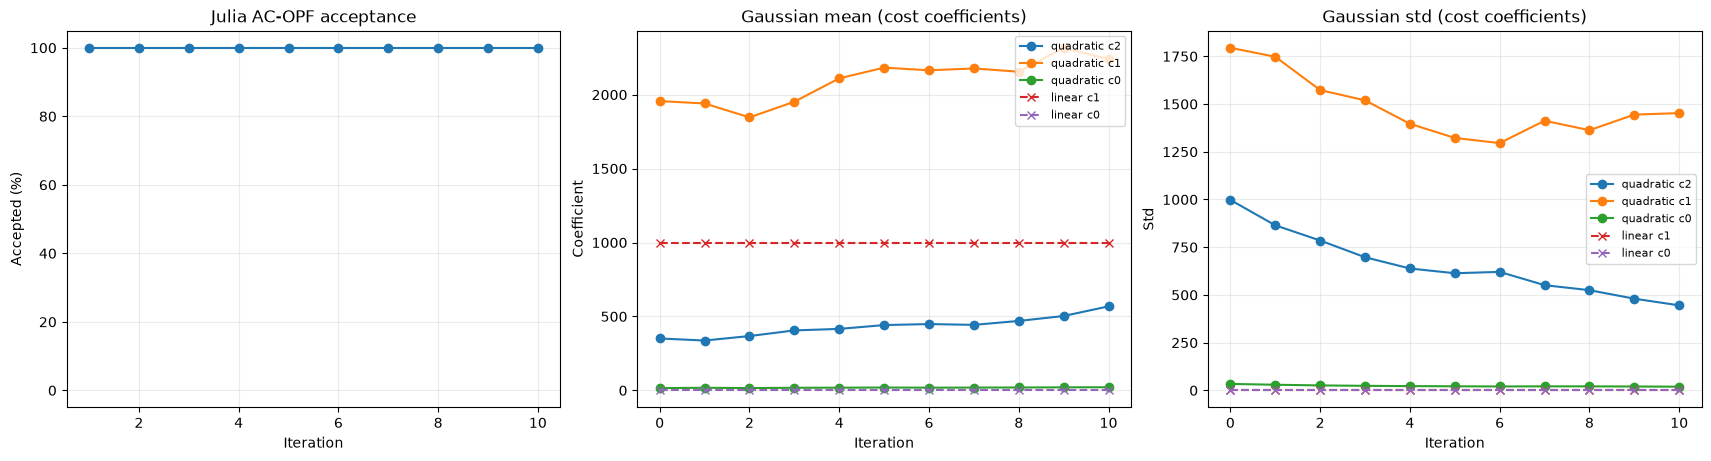

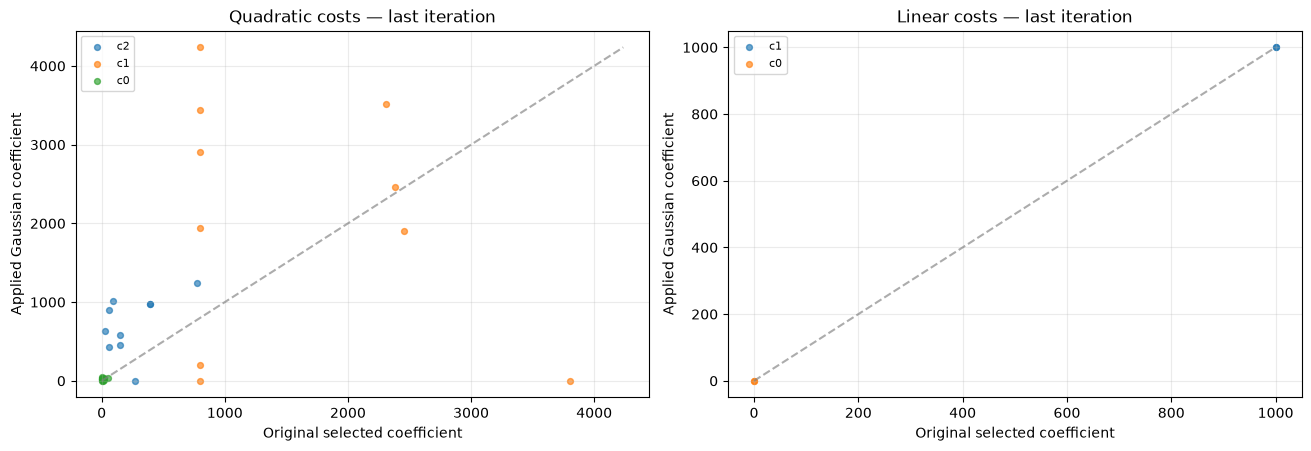

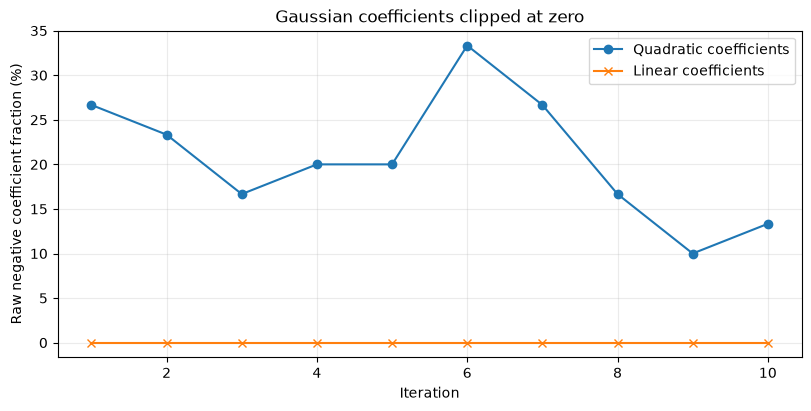

In [8]:
xs=[h["iteration"] for h in history]
fig, axes=plt.subplots(1,3,figsize=(17,4.5),constrained_layout=True)
axes[0].plot(xs,[100*h["acceptance_rate"] for h in history],marker="o")
axes[0].set(title="Julia AC-OPF acceptance",xlabel="Iteration",ylabel="Accepted (%)",ylim=(-5,105))
for j,label in enumerate(("c2","c1","c0")):
    if quad_n:
        axes[1].plot([0]+xs,[initial_quad_mu[j]]+[h["quad_mu"][j] for h in history],marker="o",label="quadratic "+label)
        axes[2].plot([0]+xs,[np.sqrt(initial_quad_cov[j,j])]+[h["quad_std"][j] for h in history],marker="o",label="quadratic "+label)
for j,label in enumerate(("c1","c0")):
    if linear_n:
        axes[1].plot([0]+xs,[initial_linear_mu[j]]+[h["linear_mu"][j] for h in history],marker="x",ls="--",label="linear "+label)
        axes[2].plot([0]+xs,[np.sqrt(initial_linear_cov[j,j])]+[h["linear_std"][j] for h in history],marker="x",ls="--",label="linear "+label)
axes[1].set(title="Gaussian mean (cost coefficients)",xlabel="Iteration",ylabel="Coefficient")
axes[2].set(title="Gaussian std (cost coefficients)",xlabel="Iteration",ylabel="Std")
for ax in axes:ax.grid(alpha=.25)
axes[1].legend(fontsize=8);axes[2].legend(fontsize=8)
fig.savefig(OUTPUT_DIR/"sampling_acceptance_and_noise.png",dpi=180,bbox_inches="tight")
plt.show()

fig,axes=plt.subplots(1,2,figsize=(13,4.4),constrained_layout=True)
for j,(kind,orig,raw,applied,labels) in enumerate([
    ("quadratic",last_original_quad,last_proposed_quad,last_applied_quad,("c2","c1","c0")),
    ("linear",last_original_linear,last_proposed_linear,last_applied_linear,("c1","c0"))]):
    ax=axes[j]
    if len(applied.reshape(-1,len(labels))):
        for k,name in enumerate(labels):
            ax.scatter(orig[:,:,k].ravel(),applied[:,:,k].ravel(),s=18,alpha=.65,label=name)
        xmin=min(float(orig.min()),float(applied.min()));xmax=max(float(orig.max()),float(applied.max()))
        ax.plot([xmin,xmax],[xmin,xmax],ls="--",color="gray",alpha=.65)
    else:
        ax.text(.5,.5,"No eligible generators in this cost family",ha="center",va="center",transform=ax.transAxes)
    ax.set(title=f"{kind.title()} costs — last iteration",xlabel="Original selected coefficient",ylabel="Applied Gaussian coefficient")
    ax.grid(alpha=.25);ax.legend(fontsize=8)
fig.savefig(OUTPUT_DIR/"cost_original_proposed_applied.png",dpi=180,bbox_inches="tight")
plt.show()

fig,ax=plt.subplots(figsize=(8,4),constrained_layout=True)
if quad_n:ax.plot(xs,[100*h["quad_clipped"] for h in history],marker="o",label="Quadratic coefficients")
if linear_n:ax.plot(xs,[100*h["linear_clipped"] for h in history],marker="x",label="Linear coefficients")
ax.set(title="Gaussian coefficients clipped at zero",xlabel="Iteration",ylabel="Raw negative coefficient fraction (%)")
ax.grid(alpha=.25);ax.legend()
fig.savefig(OUTPUT_DIR/"cost_clipping_fractions.png",dpi=180,bbox_inches="tight")
plt.show()


## 9. Export CSV verification and Gaussian history (same structure as other modes)


In [9]:
def write_csv(path,rows,fields):
    with Path(path).open("w",newline="",encoding="utf-8") as f:
        w=csv.DictWriter(f,fieldnames=fields,extrasaction="ignore")
        w.writeheader();w.writerows(rows)

log_fields=["iteration","scenario","accepted","status","termination_status","primal_status",
            "objective","solve_time","elapsed_s","reason","n_quadratic_changed",
            "n_linear_changed","selected_generator_ids"]
write_csv(OUTPUT_DIR/"verification_log.csv",verification_log,log_fields)

def row_from_history(h):
    row={k:h[k] for k in ("iteration","accepted_count","rejected_count","acceptance_rate","quad_clipped","linear_clipped","updated")}
    for prefix,mu,std,cov in (("quad",h["quad_mu"],h["quad_std"],h["quad_cov"]),
                              ("linear",h["linear_mu"],h["linear_std"],h["linear_cov"])):
        for j,val in enumerate(mu):row[f"{prefix}_mean_{j}"]=float(val)
        for j,val in enumerate(std):row[f"{prefix}_std_{j}"]=float(val)
        for j in range(len(mu)):
            for k in range(j+1,len(mu)):row[f"{prefix}_cov_{j}_{k}"]=float(cov[j,k])
    return row
history_rows=[row_from_history(h) for h in history]
write_csv(OUTPUT_DIR/"sampling_history.csv",history_rows,list(history_rows[0]))
print("Scenarios:",SCENARIO_PATH)
print("History & plots:",OUTPUT_DIR)


Scenarios: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_cost/alabama/acopf_labeled_scenarios.npz
History & plots: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_cost/alabama


## Meaning and limitations

- A 3-term *polynomial* generator cost is `[c2,c1,c0]`; a 2-term polynomial cost is `[c1,c0]`. Piecewise-linear cost models (`model==1`) and other term counts are **not perturbed**, matching the provided reference.
- Per scenario, approximately **10% of each available cost family** is selected independently; all other costs stay at their original values.
- As in the original `sampling_data_cost(3)` notebook, Gaussian draws below zero are clipped to zero, and any dataset-constant coefficient remains fixed (not artificially randomized). If an original constant is negative, it remains unchanged. Thus the *applied* values are not fully Gaussian.
- `INITIAL_SCALE` multiplies **initial covariance scale**, not the cost coefficients themselves. The mean comes from each family's empirical original costs. `alpha=0.3` updates the distributions only using Julia-accepted scenarios.
- Costs change the OPF **objective**, not its equality/inequality constraints. Therefore, when all else is equal, costs should not change the mathematical *existence* of a feasible operating point. Numerical solver accept/reject and the pretrained model's feasibility scores can still vary; don't mistake those variations for proof of physical infeasibility.
- A Julia result of `NOT_VERIFIED` is not automatically proof of mathematical infeasibility. Keep the detailed solver status from the CSV.
